In [1]:
# ============================================================
# MICROWAVE CAVITY ANALYSIS
# ============================================================
#
# Analytical and numerical investigation of:
#
#   1. Cylindrical TM010 cavity
#   2. Cylindrical TM110 cavity
#   3. Square rectangular TM210 cavity
#
# The notebook uses:
#   SymPy   -> symbolic mathematics and analytical integrals
#   NumPy   -> numerical arrays and evaluation
#   SciPy   -> Bessel-function roots
#   Matplotlib -> field visualisation
#
# All fields are represented as phasor amplitudes.
#
# The unloaded cavity Q is calculated from:
#
#       Q0 = omega * W / Pc
#
# where
#
#       W = We + Wm
#
# and
#
#       Pc = Rs/2 * integral_S |Ht|^2 dS
#
# The loaded Q due to probes, samples, etc. is deliberately
# treated separately.
# ============================================================

import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

from scipy.special import jv, jvp, jn_zeros

from IPython.display import display, Math, Markdown

# SymPy display
sp.init_printing()

# Numerical constants
mu0 = 4 * np.pi * 1e-7
eps0 = 8.8541878128e-12
c0 = 1 / np.sqrt(mu0 * eps0)

# Bessel roots useful for the cylindrical cavities
x01 = jn_zeros(0, 1)[0]
x11 = jn_zeros(1, 1)[0]

print(f"x_01 = {x01:.12f}")
print(f"x_11 = {x11:.12f}")
print(f"c0   = {c0:.6e} m/s")

x_01 = 2.404825557696
x_11 = 3.831705970208
c0   = 2.997925e+08 m/s


In [2]:
# ============================================================
# SYMBOLIC VARIABLES
# ============================================================

# Geometrical variables
a, b, c, r, x, y, z, theta = sp.symbols(
    'a b c r x y z theta',
    positive=True,
    real=True
)

# Mode/wave variables
k, omega = sp.symbols(
    'k omega',
    positive=True,
    real=True
)

# Material parameters
mu, eps, sigma, Rs = sp.symbols(
    'mu epsilon sigma R_s',
    positive=True,
    real=True
)

# Field amplitude
A = sp.symbols('A', positive=True, real=True)

# Bessel-function radial coordinate
u = sp.symbols('u', positive=True, real=True)

# Convenient symbolic notation
pi = sp.pi
j = sp.I

In [3]:
# ============================================================
# BASIC ELECTROMAGNETIC RELATIONSHIPS
# ============================================================

# Resonance relationship for a homogeneous cavity:
#
#       k^2 = omega^2 * mu * eps
#
# For the modes considered here, k is the transverse
# wavenumber because there is no z variation (l = 0).

resonance_relation = sp.Eq(
    k**2,
    omega**2 * mu * eps
)

display(Math(
    r"k^2 = \omega^2\mu\epsilon"
))

# Skin depth and surface resistance for a good conductor
delta = sp.sqrt(2 / (omega * mu * sigma))

Rs_expression = sp.sqrt(omega * mu / (2 * sigma))

display(Math(
    r"\delta = \sqrt{\frac{2}{\omega\mu\sigma}}"
))

display(Math(
    r"R_s = \sqrt{\frac{\omega\mu}{2\sigma}}"
))

# Stored energies
We_general = sp.Rational(1, 4) * eps * sp.Symbol('E_integral')
Wm_general = sp.Rational(1, 4) * mu * sp.Symbol('H_integral')

display(Math(
    r"W_e = \frac{1}{4}\int_V \epsilon|\mathbf{E}|^2\,dV"
))

display(Math(
    r"W_m = \frac{1}{4}\int_V \mu|\mathbf{H}|^2\,dV"
))

display(Math(
    r"Q_0 = \frac{\omega(W_e+W_m)}{P_c}"
))

display(Math(
    r"P_c = \frac{R_s}{2}\int_S |\mathbf{H}_t|^2\,dS"
))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [4]:
# ============================================================
# HELPER FUNCTION FOR LATEX OUTPUT
# ============================================================

def show_equation(expr, label=None):
    """
    Display a SymPy expression as a LaTeX equation.

    Parameters
    ----------
    expr : sympy expression or equality
        Expression to display.
    label : str, optional
        Text label displayed above the equation.
    """
    
    if label:
        display(Markdown(f"### {label}"))
    
    display(Math(sp.latex(expr)))

In [5]:
# ============================================================
# CYLINDRICAL TM010 CAVITY
# ============================================================
#
# Mode:
#
#       TM_010
#
# Cylindrical notation:
#
#       p = 0
#       q = 1
#       s = 0
#
# Therefore:
#
#       k a = x_01
#
# where x_01 is the first zero of J_0.
#
# Since this is a TM mode:
#
#       B = 0
# ============================================================

k_010 = sp.Symbol('k_010', positive=True, real=True)

# Radial field functions
Ez_010 = A * sp.besselj(0, k_010 * r)

Er_010 = sp.Integer(0)
Eth_010 = sp.Integer(0)

Hr_010 = sp.Integer(0)

Hth_010 = (
    -j * omega * eps / k_010**2
    * A * sp.diff(sp.besselj(0, k_010*r), r)
)

Hz_010 = sp.Integer(0)

# Replace derivative with J_0'(kr) notation if desired
display(Markdown("### TM$_{010}$ field functions"))

show_equation(sp.Eq(sp.Symbol('E_r'), Er_010))
show_equation(sp.Eq(sp.Symbol('E_\theta'), Eth_010))
show_equation(sp.Eq(sp.Symbol('E_z'), Ez_010))

show_equation(sp.Eq(sp.Symbol('H_r'), Hr_010))
show_equation(sp.Eq(sp.Symbol('H_\theta'), Hth_010))
show_equation(sp.Eq(sp.Symbol('H_z'), Hz_010))

display(Markdown(
    r"""
The radial eigenvalue is

\[
k_{010}a=x_{01},
\]

where \(x_{01}\) is the first zero of \(J_0\).
"""
))


### TM$_{010}$ field functions

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


The radial eigenvalue is

\[
k_{010}a=x_{01},
\]

where \(x_{01}\) is the first zero of \(J_0\).


In [6]:
# ============================================================
# TM010 RESONANT FREQUENCY
# ============================================================

k_010_expr = x01 / a

omega_010_expr = k_010_expr / sp.sqrt(mu * eps)

f_010_expr = sp.simplify(
    omega_010_expr / (2 * sp.pi)
)

display(Markdown("### TM$_{010}$ resonant frequency"))

show_equation(
    sp.Eq(
        sp.Symbol(r'k_{010}'),
        k_010_expr
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'\omega_{010}'),
        omega_010_expr
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'f_{010}'),
        f_010_expr
    )
)

### TM$_{010}$ resonant frequency

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [7]:
# ============================================================
# TM010 ELECTRIC STORED ENERGY
# ============================================================

theta_integral_010 = sp.integrate(
    1,
    (theta, 0, 2*pi)
)

z_integral_010 = sp.integrate(
    1,
    (z, 0, c)
)

radial_integral_010 = sp.integrate(
    r * sp.besselj(0, k_010*r)**2,
    (r, 0, a)
)

E_integral_010 = sp.simplify(
    theta_integral_010
    * z_integral_010
    * radial_integral_010
    * A**2
)

We_010 = sp.simplify(
    sp.Rational(1, 4) * eps * E_integral_010
)

display(Markdown(
    "### TM$_{010}$ electric energy integral"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'\int_V |\mathbf{E}|^2 dV'),
        E_integral_010
    )
)

display(Markdown(
    r"""
Using the boundary condition

\[
J_0(k a)=J_0(x_{01})=0,
\]

the radial integral becomes

\[
\int_0^a rJ_0^2(kr)\,dr
=
\frac{a^2}{2}J_1^2(x_{01}).
\]
"""
))

# Substitute the root condition manually
We_010_closed = (
    sp.pi * eps * c * a**2 * A**2
    * sp.besselj(1, k_010*a)**2
    / 4
)

show_equation(
    sp.Eq(
        sp.Symbol(r'W_{e,010}'),
        We_010_closed
    )
)

### TM$_{010}$ electric energy integral

<IPython.core.display.Math object>


Using the boundary condition

\[
J_0(k a)=J_0(x_{01})=0,
\]

the radial integral becomes

\[
\int_0^a rJ_0^2(kr)\,dr
=
\frac{a^2}{2}J_1^2(x_{01}).
\]


<IPython.core.display.Math object>

In [8]:
# ============================================================
# TM010 MAGNETIC STORED ENERGY
# ============================================================

# Use the identity:
#
# J_0'(x) = -J_1(x)
#
# Therefore:
#
# |H_theta|^2 =
# (omega eps A / k)^2 J_1^2(kr)

H_integral_010 = sp.integrate(
    r * sp.besselj(1, k_010*r)**2,
    (r, 0, a)
)

H_volume_integral_010 = (
    2*pi*c
    * (omega*eps*A/k_010)**2
    * H_integral_010
)

Wm_010 = sp.simplify(
    sp.Rational(1, 4)
    * mu
    * H_volume_integral_010
)

display(Markdown(
    "### TM$_{010}$ magnetic energy"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'W_{m,010}'),
        Wm_010
    )
)

#Use the boundary condition once again of J0(k_010*a)=0
Wm_010_closed = (pi*mu*c*(A*eps*omega*a)**2 *sp.besselj(1,k_010*a)**2 /(4*k_010**2))
show_equation(sp.Eq(sp.Symbol(r'Wm_{m,010}'), Wm_010_closed))


### TM$_{010}$ magnetic energy

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [9]:
# ============================================================
# TM010 CONDUCTOR LOSS
# ============================================================
#
# Pc = Rs/2 * integral_S |Ht|^2 dS
#
# There are two contributions:
#
#   1. cylindrical side wall
#   2. top and bottom end plates
# ============================================================

# Magnitude squared of H_theta:
Htheta_sq_010 = (
    (omega * eps * A / k_010)**2
    * sp.besselj(1, k_010*r)**2
)

# ------------------------------------------------------------
# Cylindrical side wall: r = a
# ------------------------------------------------------------

I_side_010 = sp.simplify(
    2*pi*c*a
    * Htheta_sq_010.subs(r, a)
)

# ------------------------------------------------------------
# End plates: z = 0 and z = c
# ------------------------------------------------------------

I_end_one_010 = sp.integrate(
    2*pi * r * Htheta_sq_010,
    (r, 0, a)
)

I_ends_010 = sp.simplify(
    2 * I_end_one_010
)

# Apply the boundary condition J0(k_010 a) = 0
I_ends_010 = sp.simplify(
    I_ends_010.subs(sp.besselj(0, k_010*a), 0)
)

I_surface_010 = sp.simplify(
    I_side_010 + I_ends_010
)

Pc_010 = sp.simplify(
    Rs / 2 * I_surface_010
)

display(Markdown(
    "### TM$_{010}$ conductor-loss integral"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'I_{ends}'), I_ends_010
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'I_{side}'), I_side_010
    )
)
show_equation(
    sp.Eq(
        sp.Symbol(r'I_{S,010}'),
        I_surface_010
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'P_{c,010}'),
        Pc_010
    )
)

# ============================================================
# TM010 UNLOADED Q
# ============================================================

Wtotal_010 = sp.simplify(
    2 * We_010_closed
)

Q_010 = sp.simplify(
    omega * Wtotal_010 / Pc_010
)

display(Markdown(
    "### Analytical unloaded $Q_0$ for TM$_{010}$"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'Q_{0,010}'),
        Q_010
    )
)

display(Markdown(
    r"""
Eliminating \(k_{010}\) via the dispersion relation
\(k_{010}=\omega\sqrt{\mu\epsilon}\) (substituted mechanically,
not retyped by hand) collapses the amplitude and Bessel-function
factors:
"""
))

# Two-step substitution eliminates k_010 in favour of omega
Q_010_final = sp.simplify(
    Q_010.subs(omega, k_010/sp.sqrt(mu*eps))
)
Q_010_final = sp.simplify(
    Q_010_final.subs(k_010, omega*sp.sqrt(mu*eps))
)

show_equation(
    sp.Eq(
        sp.Symbol(r'Q_{0,010}'),
        Q_010_final
    )
)

# Self-check against the known closed form for a TM_np0 pillbox mode
assert sp.simplify(
    Q_010_final - omega*mu*a*c/(2*Rs*(a+c))
) == 0, "TM010 Q0 does not match the expected closed form!"


### TM$_{010}$ conductor-loss integral

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Analytical unloaded $Q_0$ for TM$_{010}$

<IPython.core.display.Math object>


Eliminating \(k_{010}\) via the dispersion relation
\(k_{010}=\omega\sqrt{\mu\epsilon}\) (substituted mechanically,
not retyped by hand) collapses the amplitude and Bessel-function
factors:


<IPython.core.display.Math object>

In [10]:
# ============================================================
# CYLINDRICAL TM110 CAVITY
# ============================================================
#
# Mode:
#
#       TM_110
#
# Therefore:
#
#       p = 1
#       q = 1
#       s = 0
#
# k a = x_11
#
# where x_11 is the first zero of J_1.
# ============================================================

k_110 = sp.Symbol('k_110', positive=True, real=True)

Ez_110 = (
    A * sp.besselj(1, k_110*r)
    * sp.cos(theta)
)

Er_110 = sp.Integer(0)
Eth_110 = sp.Integer(0)

Hr_110 = (
    -j * omega * eps
    / (k_110**2 * r)
    * A * sp.besselj(1, k_110*r)
    * sp.sin(theta)
)

Hth_110 = (
    -j * omega * eps / k_110**2
    * A * sp.diff(
        sp.besselj(1, k_110*r),
        r
    )
    * sp.cos(theta)
)

Hz_110 = sp.Integer(0)

display(Markdown("### TM$_{110}$ field functions"))

show_equation(sp.Eq(sp.Symbol('E_r'), Er_110))
show_equation(sp.Eq(sp.Symbol('E_\theta'), Eth_110))
show_equation(sp.Eq(sp.Symbol('E_z'), Ez_110))

show_equation(sp.Eq(sp.Symbol('H_r'), Hr_110))
show_equation(sp.Eq(sp.Symbol('H_\theta'), Hth_110))
show_equation(sp.Eq(sp.Symbol('H_z'), Hz_110))


### TM$_{110}$ field functions

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [11]:
# ============================================================
# TM110 RESONANT FREQUENCY
# ============================================================

k_110_expr = x11 / a

omega_110_expr = k_110_expr / sp.sqrt(mu * eps)

f_110_expr = sp.simplify(
    omega_110_expr / (2*pi)
)

display(Markdown("### TM$_{110}$ resonant frequency"))

show_equation(
    sp.Eq(
        sp.Symbol(r'k_{110}'),
        k_110_expr
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'f_{110}'),
        f_110_expr
    )
)

### TM$_{110}$ resonant frequency

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [12]:
# ============================================================
# TM110 ELECTRIC STORED ENERGY
# ============================================================

# |Ez|^2 contains cos^2(theta)

theta_factor_110 = sp.integrate(
    sp.cos(theta)**2,
    (theta, 0, 2*pi)
)

radial_integral_110 = sp.integrate(
    r * sp.besselj(1, k_110*r)**2,
    (r, 0, a)
)

E_integral_110 = sp.simplify(
    A**2
    * c
    * theta_factor_110
    * radial_integral_110
)

We_110 = sp.simplify(
    eps * E_integral_110 / 4
)

display(Markdown(
    "### TM$_{110}$ electric energy"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'W_{e,110}'),
        We_110
    )
)

We_110_closed = (
    pi * eps * c * a**2 * A**2
    * sp.besselj(0, k_110*a)**2
    / 8
)

show_equation(
    sp.Eq(
        sp.Symbol(r'W_{e,110}'),
        We_110_closed
    )
)

### TM$_{110}$ electric energy

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [13]:
# ============================================================
# TM110 MAGNETIC STORED ENERGY
# ============================================================
#
# |H|^2 = |Hr|^2 + |Htheta|^2
#
# The angular dependence gives:
#
#   integral sin^2(theta) dtheta = pi
#   integral cos^2(theta) dtheta = pi
# ============================================================

H2_110 = sp.simplify(Hr_110*sp.conjugate(Hr_110)+Hth_110*sp.conjugate(Hth_110))

show_equation(sp.Eq(sp.Symbol('H^2'), H2_110))

Wm_110_raw = sp.Rational(1,4)*mu*c*sp.integrate(H2_110*r, (theta,0,2*pi), (r,0,a))

display(Markdown(
    "### TM$_{110}$ magnetic energy"
))

show_equation(sp.Eq(sp.Symbol(r'W_{m,110}'), sp.simplify(Wm_110_raw)))

# Apply the boundary condition J1(k_110 a) = 0
Wm_110_closed = sp.simplify(
    Wm_110_raw.subs(sp.besselj(1, k_110*a), 0)
)

show_equation(sp.Eq(sp.Symbol(r'W_{m,110}'), Wm_110_closed))

# Self-check: the energy theorem requires We_110 = Wm_110 at resonance
_check_110 = sp.simplify(
    (We_110_closed - Wm_110_closed).subs(omega**2, k_110**2/(mu*eps))
)
assert _check_110 == 0, "TM110: We != Wm at resonance!"


<IPython.core.display.Math object>

### TM$_{110}$ magnetic energy

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [14]:
# ============================================================
# TM110 CONDUCTOR LOSS
# ============================================================
#
# The cavity surface consists of:
#
#   1. cylindrical wall
#   2. top end plate
#   3. bottom end plate
# ============================================================

# ------------------------------------------------------------
# Cylindrical wall
# ------------------------------------------------------------

# At r = a, J1(k a) = 0, so Hr = 0.
#
# Only Htheta contributes.

Htheta_sq_110 = (
    (omega * eps * A / k_110**2)**2
    * sp.diff(
        sp.besselj(1, k_110*r),
        r
    )**2
    * sp.cos(theta)**2
)

I_side_110 = sp.simplify(
    sp.integrate(
        Htheta_sq_110.subs(r, a) * a,
        (theta, 0, 2*pi)
    ) * c
)

# Apply the boundary condition J1(k_110 a) = 0
I_side_110 = sp.simplify(
    I_side_110.subs(sp.besselj(1, k_110*a), 0)
)

# ------------------------------------------------------------
# End plates
# ------------------------------------------------------------

Hr_sq_110 = (
    (omega * eps * A)**2
    / (k_110**4 * r**2)
    * sp.besselj(1, k_110*r)**2
    * sp.sin(theta)**2
)

Htheta_sq_end_110 = Htheta_sq_110

I_one_end_110 = sp.integrate(
    sp.integrate(
        (Hr_sq_110 + Htheta_sq_end_110) * r,
        (theta, 0, 2*pi)
    ),
    (r, 0, a)
)

I_ends_110 = sp.simplify(
    2 * I_one_end_110
)

# Apply the boundary condition J1(k_110 a) = 0
I_ends_110 = sp.simplify(
    I_ends_110.subs(sp.besselj(1, k_110*a), 0)
)

I_surface_110 = sp.simplify(
    I_side_110 + I_ends_110
)

Pc_110 = sp.simplify(
    Rs / 2 * I_surface_110
)

display(Markdown(
    "### TM$_{110}$ wall-loss integral"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'I_{S,110}'),
        I_surface_110
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'P_{c,110}'),
        Pc_110
    )
)

# ============================================================
# TM110 UNLOADED Q
# ============================================================

Wtotal_110 = 2 * We_110_closed

Q_110 = sp.simplify(
    omega * Wtotal_110 / Pc_110
)

display(Markdown(
    "### Analytical unloaded $Q_0$ for TM$_{110}$"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'Q_{0,110}'),
        Q_110
    )
)

display(Markdown(
    r"""
Eliminating \(k_{110}\) via the dispersion relation
\(k_{110}=\omega\sqrt{\mu\epsilon}\) (substituted mechanically):
"""
))

Q_110_final = sp.simplify(
    Q_110.subs(omega, k_110/sp.sqrt(mu*eps))
)
Q_110_final = sp.simplify(
    Q_110_final.subs(k_110, omega*sp.sqrt(mu*eps))
)

show_equation(
    sp.Eq(
        sp.Symbol(r'Q_{0,110}'),
        Q_110_final
    )
)

# Self-check against the known closed form
assert sp.simplify(
    Q_110_final - omega*mu*a*c/(2*Rs*(a+c))
) == 0, "TM110 Q0 does not match the expected closed form!"


### TM$_{110}$ wall-loss integral

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Analytical unloaded $Q_0$ for TM$_{110}$

<IPython.core.display.Math object>


Eliminating \(k_{110}\) via the dispersion relation
\(k_{110}=\omega\sqrt{\mu\epsilon}\) (substituted mechanically):


<IPython.core.display.Math object>

In [15]:
# ============================================================
# SQUARE RECTANGULAR TM210 CAVITY
# ============================================================
#
# General rectangular notation:
#
#       TM_pqr
#
# For TM210:
#
#       p = 2
#       q = 1
#       r = 0
#
# Square cavity:
#
#       a = b
#
# Therefore:
#
#       k^2 = (2*pi/a)^2 + (pi/a)^2
#           = 5*pi^2/a^2
#
#       k = sqrt(5)*pi/a
#
# Since this is a TM mode:
#
#       B = 0
# ============================================================

k_210 = sp.sqrt(5) * pi / a

Ez_210 = (
    A
    * sp.sin(2*pi*x/a)
    * sp.sin(pi*y/a)
)

Ex_210 = sp.Integer(0)
Ey_210 = sp.Integer(0)

Hx_210 = (
    j * omega * eps * A * a
    / (5*pi)
    * sp.sin(2*pi*x/a)
    * sp.cos(pi*y/a)
)

Hy_210 = (
    -j * 2 * omega * eps * A * a
    / (5*pi)
    * sp.cos(2*pi*x/a)
    * sp.sin(pi*y/a)
)

Hz_210 = sp.Integer(0)

display(Markdown("### TM$_{210}$ square-cavity field functions"))

show_equation(sp.Eq(sp.Symbol('E_x'), Ex_210))
show_equation(sp.Eq(sp.Symbol('E_y'), Ey_210))
show_equation(sp.Eq(sp.Symbol('E_z'), Ez_210))

show_equation(sp.Eq(sp.Symbol('H_x'), Hx_210))
show_equation(sp.Eq(sp.Symbol('H_y'), Hy_210))
show_equation(sp.Eq(sp.Symbol('H_z'), Hz_210))


### TM$_{210}$ square-cavity field functions

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [16]:
# ============================================================
# TM210 RESONANT FREQUENCY
# ============================================================

omega_210_expr = sp.simplify(
    k_210 / sp.sqrt(mu * eps)
)

f_210_expr = sp.simplify(
    omega_210_expr / (2*pi)
)

display(Markdown("### TM$_{210}$ resonant frequency"))

show_equation(
    sp.Eq(
        sp.Symbol(r'k_{210}'),
        k_210
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'f_{210}'),
        f_210_expr
    )
)

### TM$_{210}$ resonant frequency

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [17]:
# ============================================================
# TM210 ELECTRIC STORED ENERGY
# ============================================================

E2_210 = Ez_210**2

E_integral_210 = sp.integrate(
    sp.integrate(
        sp.integrate(
            E2_210,
            (x, 0, a)
        ),
        (y, 0, a)
    ),
    (z, 0, c)
)

We_210 = sp.simplify(
    eps * E_integral_210 / 4
)

display(Markdown(
    "### TM$_{210}$ electric energy"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'\int_V|\mathbf E|^2dV'),
        E_integral_210
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'W_{e,210}'),
        We_210
    )
)

### TM$_{210}$ electric energy

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [18]:
# ============================================================
# TM210 MAGNETIC STORED ENERGY
# ============================================================

H2_210 = (
    sp.expand_complex(Hx_210 * sp.conjugate(Hx_210))
    +
    sp.expand_complex(Hy_210 * sp.conjugate(Hy_210))
)

# Since A, omega, eps are declared real and positive,
# simplify the expression.

H2_210 = sp.simplify(H2_210)

H_integral_210 = sp.integrate(
    sp.integrate(
        sp.integrate(
            H2_210,
            (x, 0, a)
        ),
        (y, 0, a)
    ),
    (z, 0, c)
)

Wm_210 = sp.simplify(
    mu * H_integral_210 / 4
)

display(Markdown(
    "### TM$_{210}$ magnetic energy"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'W_{m,210}'),
        Wm_210
    )
)

display(Markdown(
    r"""
At resonance,

\[
k^2=\omega^2\mu\epsilon,
\]

and the result should satisfy

\[
W_{m,210}=W_{e,210}.
\]
"""
))

# Self-check: substitute the resonance condition and compare to We_210
_Wm_210_res = sp.simplify(
    Wm_210.subs(omega**2, k_210**2/(mu*eps))
)
assert sp.simplify(_Wm_210_res - We_210) == 0, "TM210: We != Wm at resonance!"


### TM$_{210}$ magnetic energy

<IPython.core.display.Math object>


At resonance,

\[
k^2=\omega^2\mu\epsilon,
\]

and the result should satisfy

\[
W_{m,210}=W_{e,210}.
\]


In [19]:
# ============================================================
# TM210 CONDUCTOR LOSS
# ============================================================
#
# Six faces:
#
#   x = 0
#   x = a
#   y = 0
#   y = a
#   z = 0
#   z = c
#
# On each face only the magnetic-field components tangential
# to that face contribute to conductor loss.
# ============================================================

Hx_sq_210 = sp.simplify(
    Hx_210 * sp.conjugate(Hx_210)
)

Hy_sq_210 = sp.simplify(
    Hy_210 * sp.conjugate(Hy_210)
)

# ------------------------------------------------------------
# x = 0 and x = a
# ------------------------------------------------------------
#
# Tangential magnetic field:
#
#       Ht = Hy
#
# evaluated ON each face (not integrated over x).
# ------------------------------------------------------------

I_x_faces = sp.simplify(
    sp.integrate(
        Hy_sq_210.subs(x, 0),
        (y, 0, a), (z, 0, c)
    )
    +
    sp.integrate(
        Hy_sq_210.subs(x, a),
        (y, 0, a), (z, 0, c)
    )
)

# ------------------------------------------------------------
# y = 0 and y = a
# ------------------------------------------------------------
#
# Tangential magnetic field:
#
#       Ht = Hx
#
# ------------------------------------------------------------

I_y_faces = sp.simplify(
    sp.integrate(
        Hx_sq_210.subs(y, 0),
        (x, 0, a), (z, 0, c)
    )
    +
    sp.integrate(
        Hx_sq_210.subs(y, a),
        (x, 0, a), (z, 0, c)
    )
)

# ------------------------------------------------------------
# z = 0 and z = c
# ------------------------------------------------------------
#
# Both Hx and Hy are tangential. Neither depends on z (l=0),
# so the two end plates contribute equally.
# ------------------------------------------------------------

I_z_one = sp.integrate(
    sp.integrate(
        Hx_sq_210 + Hy_sq_210,
        (x, 0, a)
    ),
    (y, 0, a)
)

I_z_faces = sp.simplify(
    2 * I_z_one
)

# Total surface integral
I_surface_210 = sp.simplify(
    I_x_faces
    + I_y_faces
    + I_z_faces
)

Pc_210 = sp.simplify(
    Rs / 2 * I_surface_210
)

display(Markdown(
    "### TM$_{210}$ wall-loss contributions"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'I_{x\text{-faces}}'),
        I_x_faces
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'I_{y\text{-faces}}'),
        I_y_faces
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'I_{z\text{-faces}}'),
        I_z_faces
    )
)

show_equation(
    sp.Eq(
        sp.Symbol(r'I_{S,210}'),
        I_surface_210
    )
)


### TM$_{210}$ wall-loss contributions

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [20]:
# ============================================================
# TM210 UNLOADED Q
# ============================================================

Wtotal_210 = sp.simplify(
    We_210 + Wm_210
)

Q_210 = sp.simplify(
    omega * Wtotal_210 / Pc_210
)

display(Markdown(
    "### Analytical unloaded $Q_0$ for TM$_{210}$"
))

show_equation(
    sp.Eq(
        sp.Symbol(r'Q_{0,210}'),
        Q_210
    )
)

display(Markdown(
    r"""
Eliminating \(\epsilon\) via the resonance condition
\(k^2=5\pi^2/a^2=\omega^2\mu\epsilon\) (substituted mechanically):
"""
))

Q_210_final = sp.simplify(
    Q_210.subs(eps, k_210**2 / (omega**2 * mu))
)

show_equation(
    sp.Eq(
        sp.Symbol(r'Q_{0,210}'),
        Q_210_final
    )
)

# Self-check against the known closed form
assert sp.simplify(
    Q_210_final - omega*mu*a*c/(2*Rs*(a + 2*c))
) == 0, "TM210 Q0 does not match the expected closed form!"


### Analytical unloaded $Q_0$ for TM$_{210}$

<IPython.core.display.Math object>


Eliminating \(\epsilon\) via the resonance condition
\(k^2=5\pi^2/a^2=\omega^2\mu\epsilon\) (substituted mechanically):


<IPython.core.display.Math object>

In [21]:
# ============================================================
# NUMERICAL CAVITY PARAMETERS
# ============================================================
#
# Change these values to your actual cavity dimensions.
#
# All dimensions are in metres.
# ============================================================

# TM010 / TM110 cylindrical cavity
a_cyl = 0.050       # radius [m]
c_cyl = 0.050       # height [m]

# TM210 square cavity
a_sq = 0.050        # x/y dimension [m]
c_sq = 0.050        # height [m]

# Aluminium conductivity
sigma_al = 3.5e7    # S/m; replace with your assumed value

# Relative permeability/permittivity of empty cavity
mu_r = 1.0
eps_r = 1.0

mu_num = mu0 * mu_r
eps_num = eps0 * eps_r

# Operating frequency target
f_target = 2.45e9
omega_target = 2*np.pi*f_target

Rs_al = np.sqrt(
    omega_target * mu_num / (2*sigma_al)
)

delta_al = np.sqrt(
    2 / (omega_target * mu_num * sigma_al)
)

print(f"Aluminium surface resistance = {Rs_al:.4e} ohm")
print(f"Aluminium skin depth         = {delta_al:.4e} m")

Aluminium surface resistance = 1.6624e-02 ohm
Aluminium skin depth         = 1.7187e-06 m


In [22]:
# ============================================================
# NUMERICAL RESONANT FREQUENCIES
# ============================================================

f010_num = (
    x01 * c0
    / (2*np.pi*a_cyl)
)

f110_num = (
    x11 * c0
    / (2*np.pi*a_cyl)
)

f210_num = (
    c0 * np.sqrt(5)
    / (2*a_sq)
)

print(f"TM010 frequency = {f010_num/1e9:.6f} GHz")
print(f"TM110 frequency = {f110_num/1e9:.6f} GHz")
print(f"TM210 frequency = {f210_num/1e9:.6f} GHz")

TM010 frequency = 2.294851 GHz
TM110 frequency = 3.656478 GHz
TM210 frequency = 6.703563 GHz


C:\Users\RafIc\AppData\Local\Temp\ipykernel_30852\4258339431.py:31: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  plt.pcolormesh(


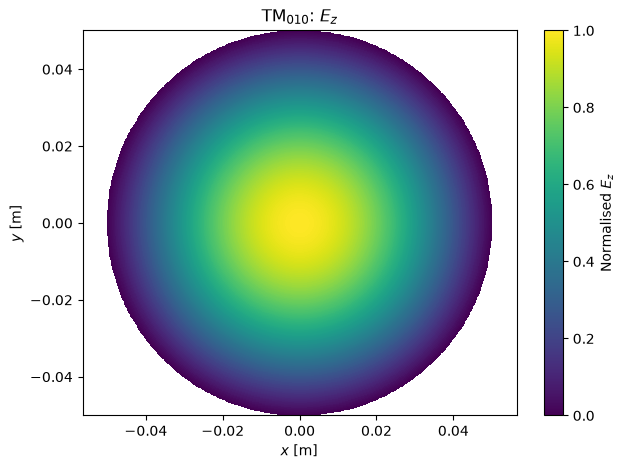

C:\Users\RafIc\AppData\Local\Temp\ipykernel_30852\4258339431.py:48: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  plt.pcolormesh(


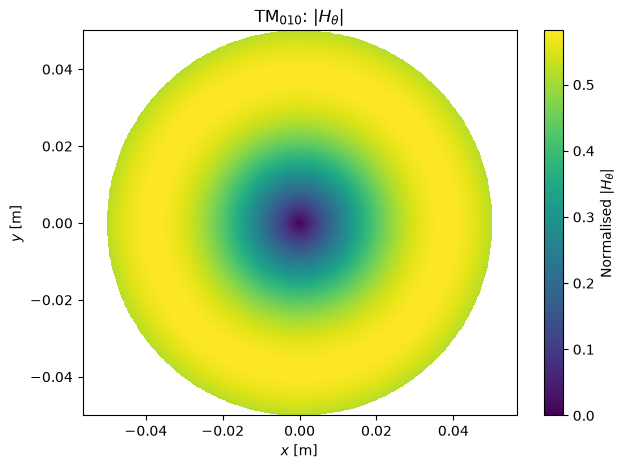

In [23]:
# ============================================================
# TM010 NUMERICAL FIELD ARRAYS
# ============================================================

Nr = 300
Ntheta = 360

r_array = np.linspace(0, a_cyl, Nr)
theta_array = np.linspace(0, 2*np.pi, Ntheta)

R, THETA = np.meshgrid(
    r_array,
    theta_array
)

k010_num = x01 / a_cyl

Ez010_num = jv(
    0,
    k010_num * R
)

Htheta010_num = jv(
    1,
    k010_num * R
)

# Plot Ez
plt.figure(figsize=(7, 5))

plt.pcolormesh(
    R * np.cos(THETA),
    R * np.sin(THETA),
    Ez010_num,
    shading='auto'
)

plt.xlabel(r'$x$ [m]')
plt.ylabel(r'$y$ [m]')
plt.title(r'TM$_{010}$: $E_z$')
plt.axis('equal')
plt.colorbar(label=r'Normalised $E_z$')
plt.show()

# Plot Htheta magnitude
plt.figure(figsize=(7, 5))

plt.pcolormesh(
    R * np.cos(THETA),
    R * np.sin(THETA),
    np.abs(Htheta010_num),
    shading='auto'
)

plt.xlabel(r'$x$ [m]')
plt.ylabel(r'$y$ [m]')
plt.title(r'TM$_{010}$: $|H_\theta|$')
plt.axis('equal')
plt.colorbar(label=r'Normalised $|H_\theta|$')
plt.show()

C:\Users\RafIc\AppData\Local\Temp\ipykernel_30852\2414866419.py:29: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  plt.pcolormesh(


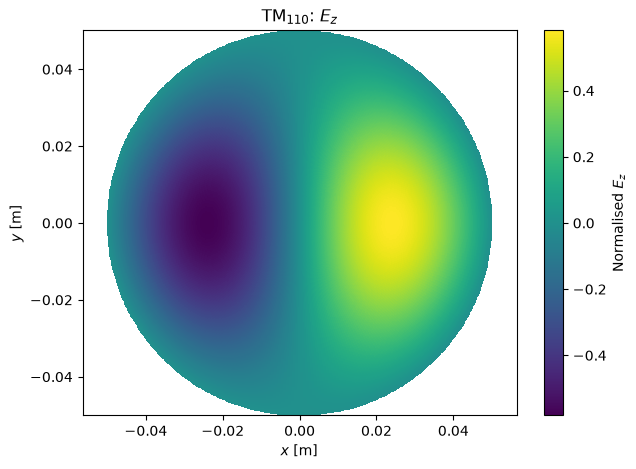

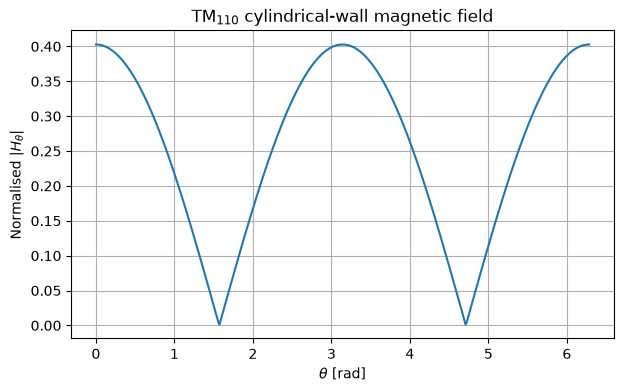

In [24]:
# ============================================================
# TM110 NUMERICAL FIELD ARRAYS
# ============================================================

k110_num = x11 / a_cyl

Ez110_num = (
    jv(1, k110_num * R)
    * np.cos(THETA)
)

Hr110_num = (
    jv(1, k110_num * R)
    / (R + 1e-15)
    * np.sin(THETA)
)

Htheta110_num = (
    jvp(1, k110_num * R)
    * np.cos(THETA)
)

# ------------------------------------------------------------
# Ez
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.pcolormesh(
    R * np.cos(THETA),
    R * np.sin(THETA),
    Ez110_num,
    shading='auto'
)

plt.xlabel(r'$x$ [m]')
plt.ylabel(r'$y$ [m]')
plt.title(r'TM$_{110}$: $E_z$')
plt.axis('equal')
plt.colorbar(label=r'Normalised $E_z$')
plt.show()

# ------------------------------------------------------------
# |H_t| on cylindrical wall
# ------------------------------------------------------------

wall_theta = np.linspace(0, 2*np.pi, 500)

Htheta_wall = (
    jvp(1, x11)
    * np.cos(wall_theta)
)

plt.figure(figsize=(7, 4))

plt.plot(
    wall_theta,
    np.abs(Htheta_wall)
)

plt.xlabel(r'$\theta$ [rad]')
plt.ylabel(r'Normalised $|H_\theta|$')
plt.title(r'TM$_{110}$ cylindrical-wall magnetic field')
plt.grid(True)
plt.show()

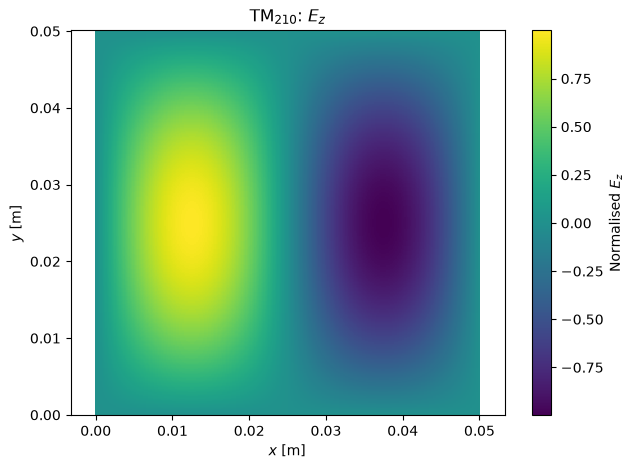

ValueError: 
|\mathbf H|
 ^
ParseFatalException: Unknown symbol: \mathbf, found '\'  (at char 1), (line:1, col:2)

<Figure size 700x500 with 2 Axes>

In [25]:
# ============================================================
# TM210 NUMERICAL FIELD ARRAYS
# ============================================================

N = 300

x_array = np.linspace(0, a_sq, N)
y_array = np.linspace(0, a_sq, N)

X, Y = np.meshgrid(
    x_array,
    y_array
)

Ez210_num = (
    np.sin(2*np.pi*X/a_sq)
    * np.sin(np.pi*Y/a_sq)
)

Hx210_num = (
    np.sin(2*np.pi*X/a_sq)
    * np.cos(np.pi*Y/a_sq)
)

Hy210_num = (
    -2
    * np.cos(2*np.pi*X/a_sq)
    * np.sin(np.pi*Y/a_sq)
)

Hmag210_num = np.sqrt(
    Hx210_num**2
    + Hy210_num**2
)

# ------------------------------------------------------------
# Ez
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.pcolormesh(
    X,
    Y,
    Ez210_num,
    shading='auto'
)

plt.xlabel(r'$x$ [m]')
plt.ylabel(r'$y$ [m]')
plt.title(r'TM$_{210}$: $E_z$')
plt.axis('equal')
plt.colorbar(label=r'Normalised $E_z$')
plt.show()

# ------------------------------------------------------------
# |H|
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.pcolormesh(
    X,
    Y,
    Hmag210_num,
    shading='auto'
)

plt.xlabel(r'$x$ [m]')
plt.ylabel(r'$y$ [m]')
plt.title(r'TM$_{210}$: $|\mathbf H|$')
plt.axis('equal')
plt.colorbar(label=r'Normalised $|\mathbf H|$')
plt.show()

In [26]:
# ============================================================
# TM010 DIMENSIONAL SENSITIVITY
# ============================================================

# Frequency:
#
#       f = x01*c0/(2*pi*a)
#
# Therefore:
#
#       df/da = -f/a
#
# and approximately:
#
#       Delta f/f = -Delta a/a

da = sp.symbols(
    r'\Delta a',
    real=True
)

f010_symbolic = (
    x01 * sp.Symbol('c_0')
    / (2*pi*a)
)

df_da_010 = sp.diff(
    f010_symbolic,
    a
)

display(Markdown(
    r"""
For TM$_{010}$,

\[
f_{010}
=
\frac{x_{01}c_0}{2\pi a}.
\]

Therefore
"""
))

show_equation(
    sp.Eq(
        sp.Symbol(r'\frac{\partial f}{\partial a}'),
        df_da_010
    )
)

display(Markdown(
    r"""
and hence, to first order,

\[
\boxed{
\frac{\Delta f}{f}
\approx
-\frac{\Delta a}{a}.
}
\]
"""
))


For TM$_{010}$,

\[
f_{010}
=
\frac{x_{01}c_0}{2\pi a}.
\]

Therefore


<IPython.core.display.Math object>


and hence, to first order,

\[
\boxed{
\frac{\Delta f}{f}
\approx
-\frac{\Delta a}{a}.
}
\]


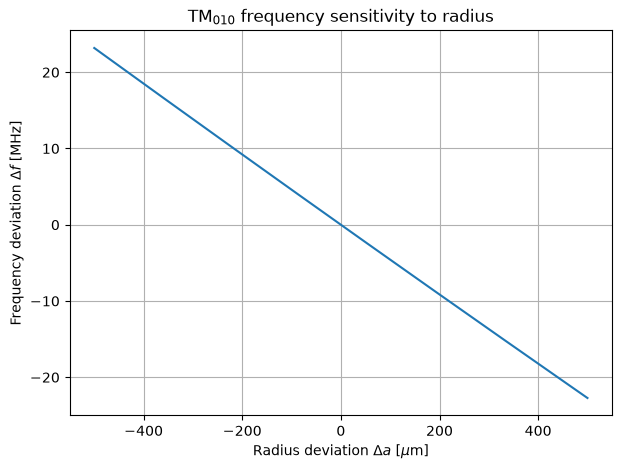

In [27]:
# ============================================================
# FREQUENCY ERROR DUE TO TM010 RADIUS ERROR
# ============================================================

# Manufacturing deviations
delta_a_values = np.linspace(
    -500e-6,
    500e-6,
    501
)

f_ideal = x01 * c0 / (2*np.pi*a_cyl)

f_perturbed = (
    x01 * c0
    / (2*np.pi*(a_cyl + delta_a_values))
)

delta_f = f_perturbed - f_ideal

plt.figure(figsize=(7, 5))

plt.plot(
    delta_a_values * 1e6,
    delta_f / 1e6
)

plt.xlabel(r'Radius deviation $\Delta a$ [$\mu$m]')
plt.ylabel(r'Frequency deviation $\Delta f$ [MHz]')
plt.title(r'TM$_{010}$ frequency sensitivity to radius')
plt.grid(True)
plt.show()

In [28]:
# ============================================================
# NUMERICAL UNLOADED Q FUNCTION
# ============================================================
#
# This function uses:
#
#       Q0 = omega * W / Pc
#
# rather than assuming the final analytical expression.
#
# This makes it useful later when additional loss terms are
# added.
# ============================================================

def cavity_Q(omega_value, W_value, Pc_value):
    """
    Calculate unloaded cavity Q.

    Parameters
    ----------
    omega_value : float
        Angular resonant frequency [rad/s].

    W_value : float
        Total stored electromagnetic energy [J].

    Pc_value : float
        Average conductor loss [W].

    Returns
    -------
    float
        Unloaded cavity quality factor.
    """
    
    return omega_value * W_value / Pc_value

# ============================================================
# ANALYTICAL Q EVALUATION
# ============================================================

# TM010
omega010_num = 2*np.pi*f010_num

Q010_num = (
    omega010_num
    * mu_num
    * a_cyl
    * c_cyl
    /
    (
        2 * Rs_al
        * (a_cyl + c_cyl)
    )
)

# TM110
omega110_num = 2*np.pi*f110_num

Q110_num = (
    omega110_num
    * mu_num
    * a_cyl
    * c_cyl
    /
    (
        2 * Rs_al
        * (a_cyl + c_cyl)
    )
)

# TM210
omega210_num = 2*np.pi*f210_num

Q210_num = (
    omega210_num
    * mu_num
    * a_sq
    * c_sq
    /
    (
        2 * Rs_al
        * (a_sq + 2*c_sq)
    )
)

print(f"TM010 unloaded Q ≈ {Q010_num:.1f}")
print(f"TM110 unloaded Q ≈ {Q110_num:.1f}")
print(f"TM210 unloaded Q ≈ {Q210_num:.1f}")


TM010 unloaded Q ≈ 13624.6
TM110 unloaded Q ≈ 21708.7
TM210 unloaded Q ≈ 26532.9
